In [510]:
#Import libaries
import pandas as pd 
import numpy as np

In [511]:
path = '/Users/sivhoung/Desktop/Year 4 intern project/Project code /dataset/processed dataset/final_df_(distance).parquet'
clean_df = pd.read_parquet(path)

In [512]:
clean_df.dtypes

order_id                                  object
customer_id                               object
order_status                              object
order_purchase_timestamp          datetime64[ns]
order_approved_at                 datetime64[ns]
order_delivered_carrier_date      datetime64[ns]
order_delivered_customer_date     datetime64[ns]
order_estimated_delivery_date     datetime64[ns]
item_count                               float64
total_price                              float64
total_freight_value                      float64
n_unique_products                        float64
n_unique_sellers                         float64
total_product_weight_g                   float64
average_product_length_cm                float64
average_product_height_cm                float64
average_product_width_cm                 float64
n_unique_categories                      float64
n_unique_seller_city                     float64
n_unique_seller_state                    float64
total_payment_value 

In [513]:
imputation_candidates = [
    'total_price',
    'total_freight_value',
    'total_product_weight_g',
    'average_product_length_cm',
    'average_product_height_cm',
    'average_product_width_cm',
    'total_payment_value',
    'max_payment_installments'
]

clean_df[imputation_candidates].isna().sum()

total_price                  775
total_freight_value          775
total_product_weight_g       775
average_product_length_cm    791
average_product_height_cm    791
average_product_width_cm     791
total_payment_value            1
max_payment_installments       1
dtype: int64

In [514]:
clean_df.isna().sum()

order_id                            0
customer_id                         0
order_status                        0
order_purchase_timestamp            0
order_approved_at                 160
order_delivered_carrier_date     1783
order_delivered_customer_date    2965
order_estimated_delivery_date       0
item_count                        775
total_price                       775
total_freight_value               775
n_unique_products                 775
n_unique_sellers                  775
total_product_weight_g            775
average_product_length_cm         791
average_product_height_cm         791
average_product_width_cm          791
n_unique_categories               775
n_unique_seller_city              775
n_unique_seller_state             775
total_payment_value                 1
max_payment_installments            1
n_unique_payment_types              1
customer_city                       0
customer_state                      0
delivery_delay                   2965
delivery_del

In [515]:
missing_item_orders = clean_df[
    clean_df["item_count"].isna()
]

missing_item_orders["order_status"].value_counts()

order_status
unavailable    603
canceled       164
created          5
invoiced         2
shipped          1
Name: count, dtype: int64

In [516]:
missing_item_orders[
    [
        "order_status",
        "order_purchase_timestamp",
        "order_approved_at"
    ]
].head(20)

,order_status,order_purchase_timestamp,order_approved_at
266,unavailable,2017-11-16 15:09:28,2017-11-16 15:26:57
586,unavailable,2018-01-31 11:31:37,2018-01-31 14:23:50
687,unavailable,2017-08-14 17:38:02,2017-08-17 00:15:18
737,unavailable,2018-01-08 19:39:03,2018-01-09 07:26:08
1130,canceled,2018-08-28 15:26:39,NaT
1160,unavailable,2017-09-27 20:55:33,2017-09-28 01:32:50
1579,unavailable,2017-08-24 11:04:41,2017-08-24 11:15:11
1801,canceled,2018-09-20 13:54:16,NaT
1826,unavailable,2017-11-30 07:48:24,2017-11-30 08:14:42
1868,canceled,2017-03-04 12:14:30,NaT


In [517]:
model_df = clean_df.dropna(
    subset=["is_delayed"]
).copy()

print(model_df.shape)
print(model_df["order_status"].value_counts())

(96453, 29)
order_status
delivered    96447
canceled         6
Name: count, dtype: int64


In [518]:
missing_summary = (
    model_df.isna()
    .sum()
    .sort_values(ascending=False)
)

missing_summary = missing_summary[missing_summary > 0]

missing_summary

average_distance_km             476
average_product_height_cm        16
average_product_width_cm         16
average_product_length_cm        16
order_approved_at                14
n_unique_payment_types            1
max_payment_installments          1
total_payment_value               1
order_delivered_carrier_date      1
dtype: int64

In [519]:
candidate_features = [
    "total_price",
    "total_freight_value",
    "total_product_weight_g",
    "average_product_length_cm",
    "average_product_height_cm",
    "average_product_width_cm",
    "item_count",
    "n_unique_products",
    "n_unique_sellers",
    "n_unique_categories",
    "total_payment_value",
    "max_payment_installments",
    "n_unique_payment_types"
]

In [520]:
distribution_summary = model_df[candidate_features].agg(
    ["count", "mean", "median", "std", "min", "max"]
).T

distribution_summary["skewness"] = (
    model_df[candidate_features].skew()
)

distribution_summary

,count,mean,median,std,min,max,skewness
total_price,96453.0,137.031885,86.50,209.068031,0.85,13440.00,9.885048
total_freight_value,96453.0,22.782810,17.17,21.558467,0.00,1794.96,12.281025
total_product_weight_g,96453.0,2385.790105,750.00,4768.735655,0.00,184400.00,6.575561
average_product_length_cm,96437.0,30.085202,25.00,16.046340,7.00,105.00,1.763894
average_product_height_cm,96437.0,16.444292,13.00,13.240887,2.00,105.00,2.262161
average_product_width_cm,96437.0,23.009979,20.00,11.686322,6.00,118.00,1.712195
item_count,96453.0,1.141966,1.00,0.538362,1.00,21.00,7.564902
n_unique_products,96453.0,1.038350,1.00,0.227572,1.00,8.00,8.101192
n_unique_sellers,96453.0,1.013706,1.00,0.122775,1.00,5.00,9.960843
n_unique_categories,96453.0,0.993717,1.00,0.146999,0.00,3.00,-1.555950


In [521]:
correlation_matrix = model_df[candidate_features].corr()

correlation_matrix

,total_price,total_freight_value,total_product_weight_g,average_product_length_cm,average_product_height_cm,average_product_width_cm,item_count,n_unique_products,n_unique_sellers,n_unique_categories,total_payment_value,max_payment_installments,n_unique_payment_types
total_price,1.000000,0.411207,0.349449,0.144310,0.228050,0.169087,0.153567,0.063159,0.042594,0.024935,0.995937,0.316261,0.036203
total_freight_value,0.411207,1.000000,0.640117,0.258132,0.334930,0.264695,0.439183,0.197212,0.132519,0.076724,0.491490,0.200804,0.026665
total_product_weight_g,0.349449,0.640117,1.000000,0.412772,0.528890,0.449585,0.229485,0.083392,0.051622,0.041633,0.396993,0.191536,0.018417
average_product_length_cm,0.144310,0.258132,0.412772,1.000000,0.195697,0.550491,0.007609,-0.004736,0.005703,0.030245,0.163394,0.125480,0.013775
average_product_height_cm,0.228050,0.334930,0.528890,0.195697,1.000000,0.288560,0.017625,-0.027127,-0.007351,0.014507,0.250882,0.137298,0.016269
average_product_width_cm,0.169087,0.264695,0.449585,0.550491,0.288560,1.000000,-0.004414,0.005622,0.005446,0.032010,0.187672,0.151039,0.017961
item_count,0.153567,0.439183,0.229485,0.007609,0.017625,-0.004414,1.000000,0.472955,0.283492,0.132061,0.190058,0.067770,0.004658
n_unique_products,0.063159,0.197212,0.083392,-0.004736,-0.027127,0.005622,0.472955,1.000000,0.593090,0.271259,0.079833,0.073563,0.007049
n_unique_sellers,0.042594,0.132519,0.051622,0.005703,-0.007351,0.005446,0.283492,0.593090,1.000000,0.363815,0.053857,0.063157,0.003950
n_unique_categories,0.024935,0.076724,0.041633,0.030245,0.014507,0.032010,0.132061,0.271259,0.363815,1.000000,0.031449,0.040022,-0.002768


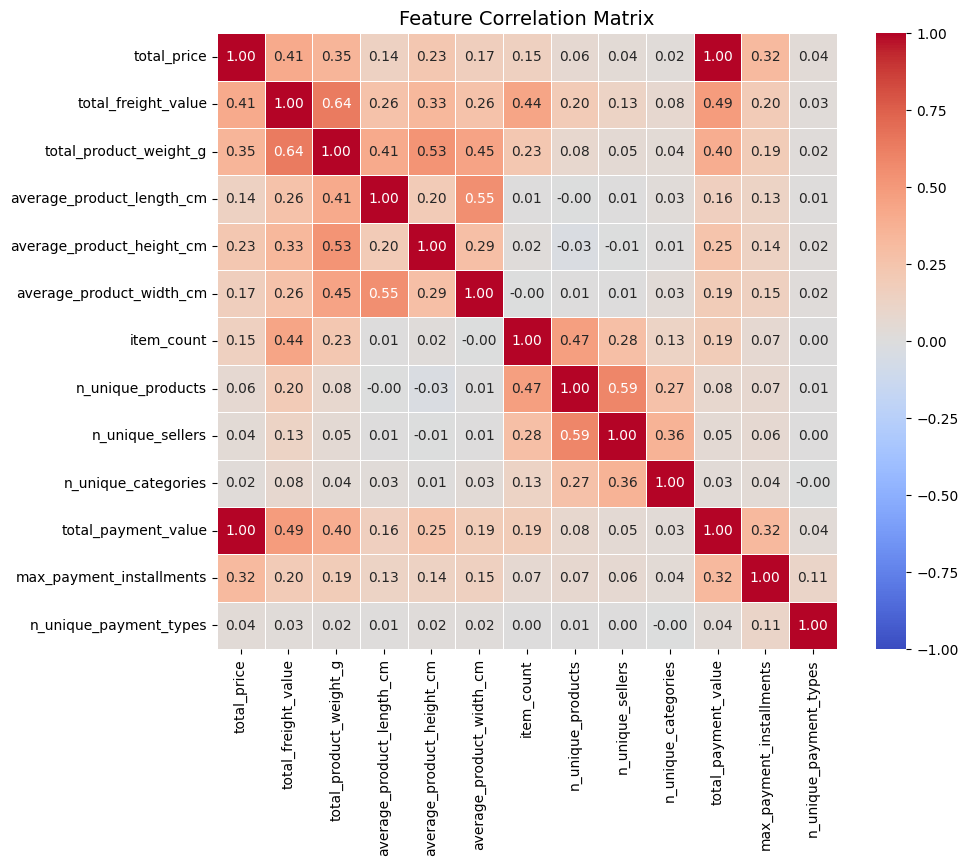

In [522]:
import matplotlib.pyplot as plt
import seaborn as sns

# Set up the figure size
plt.figure(figsize=(10, 8))

# Create the heatmap
sns.heatmap(
    correlation_matrix,
    annot=True,  # Shows the actual correlation numbers inside the boxes
    cmap="coolwarm",  # Color scheme: blue (negative) to red (positive)
    fmt=".2f",  # Rounds numbers to 2 decimal places
    linewidths=0.5,  # Adds tiny white grid lines between boxes
    vmin=-1,
    vmax=1,  # Anchors the color scale from -1 to 1
)

# Add a title and display it
plt.title("Feature Correlation Matrix", fontsize=14)
plt.show()

In [523]:
group_summary = (
    model_df
    .groupby("is_delayed")[candidate_features]
    .agg(["mean", "median", "std"])
    .T
)

group_summary

is_delayed                              False        True 
total_price               mean     136.056980   148.070845
                          median    85.500000    89.900000
                          std      207.462634   226.174720
total_freight_value       mean      22.620357    24.622275
                          median    17.060000    18.050000
                          std       21.434886    22.832271
total_product_weight_g    mean    2362.319579  2651.549508
                          median   750.000000   800.000000
                          std     4712.448889  5358.201682
average_product_length_cm mean      30.005300    30.989778
                          median    25.000000    25.000000
                          std       15.933008    17.252915
average_product_height_cm mean      16.391422    17.042840
                          median    13.000000    13.000000
                          std       13.142574    14.294133
average_product_width_cm  mean      22.986013    23.281299
                          median    20.000000    20.000000
                          std       11.625941    12.346861
item_count                mean       1.144484     1.113453
                          median     1.000000     1.000000
                          std        0.541376     0.502136
n_unique_products         mean       1.039830     1.021592
                          median     1.000000     1.000000
                          std        0.232662     0.157993
n_unique_sellers          mean       1.014714     1.002300
                          median     1.000000     1.000000
                          std        0.127239     0.047903
n_unique_categories       mean       0.994324     0.986840
                          median     1.000000     1.000000
                          std        0.148339     0.130679
total_payment_value       mean     158.707420   172.717976
                          median   104.610000   112.235000
                          std      217.139173   236.842676
max_payment_installments  mean       2.970810     3.055584
                          median     2.000000     2.000000
                          std        2.732578     2.794033
n_unique_payment_types    mean       1.008733     1.009456
                          median     1.000000     1.000000
                          std        0.093165     0.098097

In [524]:
selected_candidates = [
    "total_price",
    "total_freight_value",
    "total_product_weight_g",
    "average_product_length_cm",
    "average_product_height_cm",
    "average_product_width_cm",
    "item_count",
    "max_payment_installments"
]

#### point-biserial correlation

In [525]:
from scipy.stats import pointbiserialr

correlation_with_target = {}

for feature in candidate_features:
    valid_data = model_df[[feature, "is_delayed"]].dropna()

    r, p = pointbiserialr(
        valid_data["is_delayed"],
        valid_data[feature]
    )

    correlation_with_target[feature] = {
        "correlation": r,
        "p_value": p
    }

target_correlation = pd.DataFrame(correlation_with_target).T

target_correlation.sort_values("correlation", ascending=False)

/Library/Frameworks/Python.framework/Versions/3.11/lib/python3.11/site-packages/scipy/stats/_stats_py.py:4776: RuntimeWarning: overflow encountered in vecdot
  r = xp.vecdot(xm / normxm, ym / normym, axis=axis)
/Library/Frameworks/Python.framework/Versions/3.11/lib/python3.11/site-packages/scipy/stats/_stats_py.py:4776: RuntimeWarning: overflow encountered in vecdot
  r = xp.vecdot(xm / normxm, ym / normym, axis=axis)
/Library/Frameworks/Python.framework/Versions/3.11/lib/python3.11/site-packages/scipy/stats/_stats_py.py:4776: RuntimeWarning: overflow encountered in vecdot
  r = xp.vecdot(xm / normxm, ym / normym, axis=axis)
/Library/Frameworks/Python.framework/Versions/3.11/lib/python3.11/site-packages/scipy/stats/_stats_py.py:4776: RuntimeWarning: overflow encountered in vecdot
  r = xp.vecdot(xm / normxm, ym / normym, axis=axis)
/Library/Frameworks/Python.framework/Versions/3.11/lib/python3.11/site-packages/scipy/stats/_stats_py.py:4776: RuntimeWarning: overflow encountered in vecdo

,correlation,p_value
total_freight_value,0.025357,3.375592e-15
total_payment_value,0.017481,5.650781e-08
average_product_length_cm,0.016754,1.958381e-07
total_product_weight_g,0.016562,2.691905e-07
total_price,0.015691,1.096515e-06
average_product_height_cm,0.013435,3.015313e-05
max_payment_installments,0.008455,8.642301e-03
average_product_width_cm,0.006900,3.212861e-02
n_unique_payment_types,0.002108,5.127303e-01
n_unique_categories,-0.013902,1.576043e-05


In [526]:
final_features = [
    "total_price",
    "total_freight_value",
    "total_product_weight_g",
    "average_product_length_cm",
    "average_product_height_cm",
    "item_count",
    "max_payment_installments"
]

model_df[final_features].isna().sum()

total_price                   0
total_freight_value           0
total_product_weight_g        0
average_product_length_cm    16
average_product_height_cm    16
item_count                    0
max_payment_installments      1
dtype: int64

In [527]:
experimental_df = model_df.dropna(subset=final_features).copy()

In [528]:
print(experimental_df.shape)
print(experimental_df[final_features].isna().sum())

(96436, 29)
total_price                  0
total_freight_value          0
total_product_weight_g       0
average_product_length_cm    0
average_product_height_cm    0
item_count                   0
max_payment_installments     0
dtype: int64


In [529]:
experimental_df[
    [
        "total_price",
        "total_freight_value",
        "total_product_weight_g",
        "item_count"
    ]
].describe()

,total_price,total_freight_value,total_product_weight_g,item_count
count,96436.000000,96436.000000,96436.000000,96436.000000
mean,137.028749,22.783884,2386.179570,1.141949
std,209.002619,21.560037,4769.056526,0.538360
min,0.850000,0.000000,0.000000,1.000000
25%,45.900000,13.850000,300.000000,1.000000
50%,86.500000,17.170000,750.000000,1.000000
75%,149.900000,24.010000,2050.000000,1.000000
max,13440.000000,1794.960000,184400.000000,21.000000


In [530]:
experimental_df[
    [
        "total_price",
        "total_freight_value",
        "total_product_weight_g",
        "item_count"
    ]
].corr()["total_price"]

total_price               1.000000
total_freight_value       0.411338
total_product_weight_g    0.349604
item_count                0.153660
Name: total_price, dtype: float64

## MCAR injection

In [531]:
random_seed = 42
missing_rate = 0.1

df_mcar = experimental_df.copy()

total_rows = len(df_mcar)
num_missing = int(total_rows * missing_rate)

np.random.seed(random_seed)
missing_indices = np.random.choice(df_mcar.index, size=num_missing, replace=False)

df_mcar.loc[missing_indices, "total_price"] = np.nan

print(f"Total rows: {total_rows}")
print(f"Missing values in total_price: {df_mcar['total_price'].isna().sum()}")
print(f"Missing rate: {df_mcar['total_price'].isna().mean():.4%}\n")

print(df_mcar[final_features].isna().sum())


Total rows: 96436
Missing values in total_price: 9643
Missing rate: 9.9994%

total_price                  9643
total_freight_value             0
total_product_weight_g          0
average_product_length_cm       0
average_product_height_cm       0
item_count                      0
max_payment_installments        0
dtype: int64


## MAR Injection

In [532]:
mar_df = experimental_df.copy()

#standardize the total_freight_value column to create a MAR score
mar_df["mar_score"] = (
    mar_df["total_freight_value"]
    - mar_df["total_freight_value"].mean()
) / mar_df["total_freight_value"].std()

In [533]:
print(mar_df["mar_score"].describe())

count    9.643600e+04
mean    -2.681961e-17
std      1.000000e+00
min     -1.056765e+00
25%     -4.143724e-01
50%     -2.603838e-01
75%      5.686987e-02
max      8.219727e+01
Name: mar_score, dtype: float64


In [534]:
#total_freight_value is right_skewed, so we will use the log transformation to make it more normally distributed
mar_df = experimental_df.copy()

mar_df["freight_log"] = np.log1p(mar_df["total_freight_value"])

mar_df["mar_score"] = (
    mar_df["freight_log"] - mar_df["freight_log"].mean()
) / mar_df["freight_log"].std()

print(mar_df["mar_score"].describe())

count    9.643600e+04
mean     3.259614e-16
std      1.000000e+00
min     -5.370891e+00
25%     -5.193018e-01
50%     -1.564719e-01
75%      4.180654e-01
max      8.103679e+00
Name: mar_score, dtype: float64


In [535]:
mar_df["mar_weight"] = np.exp(mar_df["mar_score"])

In [536]:
print(mar_df["mar_weight"].describe())

count    96436.000000
mean         2.076621
std         13.175017
min          0.004650
25%          0.594936
50%          0.855156
75%          1.519020
max       3306.612139
Name: mar_weight, dtype: float64


In [537]:
#since weight sampling creates extreme right_skew, so we shfit it to aLinear Positive Weight
mar_df["mar_weight"] = mar_df["mar_score"] - mar_df["mar_score"].min() + 1

print(mar_df["mar_weight"].describe())


count    96436.000000
mean         6.370891
std          1.000000
min          1.000000
25%          5.851589
50%          6.214419
75%          6.788956
max         14.474570
Name: mar_weight, dtype: float64


In [538]:
np.random.seed(random_seed)

missing_indices_mar = np.random.choice(
    mar_df.index,
    size=num_missing,
    replace=False,
    p=mar_df["mar_weight"] / mar_df["mar_weight"].sum()
)

In [539]:
print(len(missing_indices_mar))
print(len(set(missing_indices_mar)))

9643
9643


In [540]:
df_mar = experimental_df.copy()

df_mar.loc[missing_indices_mar, "total_price"] = np.nan

In [541]:
print(f"Total rows: {len(df_mar)}")
print(f"Missing values in total_price: {df_mar['total_price'].isna().sum()}")
print(f"Missing rate: {df_mar['total_price'].isna().mean():.4%}")

Total rows: 96436
Missing values in total_price: 9643
Missing rate: 9.9994%


In [542]:
print(
    "Mean freight value - missing:",
    df_mar.loc[df_mar["total_price"].isna(), "total_freight_value"].mean()
)

print(
    "Mean freight value - observed:",
    df_mar.loc[df_mar["total_price"].notna(), "total_freight_value"].mean()
)

Mean freight value - missing: 25.821978637353517
Mean freight value - observed: 22.446340833938223


## MNAR Injection

In [543]:
mnar_df = experimental_df.copy()

mnar_df["mnar_score"] = (
    np.log1p(mnar_df["total_price"])
    - np.log1p(mnar_df["total_price"]).mean()
) / np.log1p(mnar_df["total_price"]).std()

print(mnar_df["mnar_score"].describe())

count    9.643600e+04
mean    -8.560170e-16
std      1.000000e+00
min     -4.193641e+00
25%     -6.661166e-01
50%      1.435139e-02
75%      6.090081e-01
max      5.507696e+00
Name: mnar_score, dtype: float64


In [544]:
mnar_df["mnar_weight"] = (
    mnar_df["mnar_score"] - mnar_df["mnar_score"].min() + 1
)

print(mnar_df["mnar_weight"].describe())

count    96436.000000
mean         5.193641
std          1.000000
min          1.000000
25%          4.527524
50%          5.207992
75%          5.802649
max         10.701337
Name: mnar_weight, dtype: float64


In [545]:
np.random.seed(random_seed)

missing_indices_mnar = np.random.choice(
    mnar_df.index,
    size=num_missing,
    replace=False,
    p=mnar_df["mnar_weight"] / mnar_df["mnar_weight"].sum()
)

In [546]:
print(len(missing_indices_mnar))
print(len(set(missing_indices_mnar)))

9643
9643


In [547]:
df_mnar = experimental_df.copy()

df_mnar.loc[missing_indices_mnar, "total_price"] = np.nan

In [548]:
print(f"Total rows: {len(df_mnar)}")
print(f"Missing values in total_price: {df_mnar['total_price'].isna().sum()}")
print(f"Missing rate: {df_mnar['total_price'].isna().mean():.4%}")

Total rows: 96436
Missing values in total_price: 9643
Missing rate: 9.9994%


In [549]:
print(
    "Original price - missing group:",
    experimental_df.loc[
        missing_indices_mnar, "total_price"
    ].mean()
)

print(
    "Original price - observed group:",
    experimental_df.loc[
        ~experimental_df.index.isin(missing_indices_mnar),
        "total_price"
    ].mean()
)

Original price - missing group: 167.20373638909052
Original price - observed group: 133.67620395654032


### 30% missing injection

In [550]:
missing_rate = 0.3
num_missing = int(len(experimental_df) * missing_rate)

print(f"Total rows: {len(experimental_df)}")
print(f"Number to make missing: {num_missing}")

Total rows: 96436
Number to make missing: 28930


In [551]:
#MCAR 30%
mcar_df = experimental_df.copy()

np.random.seed(random_seed)

missing_indices_mcar = np.random.choice(
    mcar_df.index,
    size=num_missing,
    replace=False
)

df_mcar_30 = experimental_df.copy()

df_mcar_30.loc[
    missing_indices_mcar,
    "total_price"
] = np.nan

In [552]:
print(f"Total rows: {len(df_mcar_30)}")
print(f"Missing values: {df_mcar_30['total_price'].isna().sum()}")
print(f"Missing rate: {df_mcar_30['total_price'].isna().mean():.4%}")

Total rows: 96436
Missing values: 28930
Missing rate: 29.9992%


In [553]:
#MAR 30%
mar_df = experimental_df.copy()

mar_df["freight_log"] = np.log1p(
    mar_df["total_freight_value"]
)

mar_df["mar_score"] = (
    mar_df["freight_log"] - mar_df["freight_log"].mean()
) / mar_df["freight_log"].std()

mar_df["mar_weight"] = (
    mar_df["mar_score"] - mar_df["mar_score"].min() + 1
)

In [554]:
np.random.seed(random_seed)

missing_indices_mar_30 = np.random.choice(
    mar_df.index,
    size=num_missing,
    replace=False,
    p=mar_df["mar_weight"] / mar_df["mar_weight"].sum()
)

In [555]:
df_mar_30 = experimental_df.copy()

df_mar_30.loc[
    missing_indices_mar_30,
    "total_price"
] = np.nan

In [556]:
print(f"Total rows: {len(df_mar_30)}")
print(f"Missing values: {df_mar_30['total_price'].isna().sum()}")
print(f"Missing rate: {df_mar_30['total_price'].isna().mean():.4%}")

Total rows: 96436
Missing values: 28930
Missing rate: 29.9992%


In [557]:
missing_group = experimental_df.loc[
    missing_indices_mar_30,
    "total_freight_value"
]

observed_group = experimental_df.drop(
    index=missing_indices_mar_30
)["total_freight_value"]

print("Missing group mean:", missing_group.mean())
print("Observed group mean:", observed_group.mean())

Missing group mean: 25.074107155202213
Observed group mean: 21.80239800906586


In [558]:
#MCAR 30%
mnar_df = experimental_df.copy()

mnar_log = np.log1p(mnar_df["total_price"])

mnar_df["mnar_score"] = (
    mnar_log - mnar_log.mean()
) / mnar_log.std()

mnar_df["mnar_weight"] = (
    mnar_df["mnar_score"]
    - mnar_df["mnar_score"].min()
    + 1
)

In [559]:
np.random.seed(random_seed)

missing_indices_mnar_30 = np.random.choice(
    mnar_df.index,
    size=num_missing,
    replace=False,
    p=mnar_df["mnar_weight"] / mnar_df["mnar_weight"].sum()
)

In [560]:
df_mnar_30 = experimental_df.copy()

df_mnar_30.loc[
    missing_indices_mnar_30,
    "total_price"
] = np.nan

In [561]:
print(f"Total rows: {len(df_mnar_30)}")
print(f"Missing values: {df_mnar_30['total_price'].isna().sum()}")
print(f"Missing rate: {df_mnar_30['total_price'].isna().mean():.4%}")

Total rows: 96436
Missing values: 28930
Missing rate: 29.9992%


In [562]:
missing_group = experimental_df.loc[
    missing_indices_mnar_30,
    "total_price"
]

observed_group = experimental_df.drop(
    index=missing_indices_mnar_30
)["total_price"]

print("Missing group mean:", missing_group.mean())
print("Observed group mean:", observed_group.mean())

Missing group mean: 160.9889754580021
Observed group mean: 126.76048558646642


### 50% missing injection

In [563]:
# MCAR 50%

missing_rate = 0.5
num_missing = int(len(experimental_df) * missing_rate)

print(f"Total rows: {len(experimental_df)}")
print(f"Number to make missing: {num_missing}")

mcar_df = experimental_df.copy()

np.random.seed(random_seed)

missing_indices_mcar_50 = np.random.choice(
    mcar_df.index,
    size=num_missing,
    replace=False
)

df_mcar_50 = experimental_df.copy()

df_mcar_50.loc[
    missing_indices_mcar_50,
    "total_price"
] = np.nan

print(f"Total rows: {len(df_mcar_50)}")
print(f"Missing values: {df_mcar_50['total_price'].isna().sum()}")
print(f"Missing rate: {df_mcar_50['total_price'].isna().mean():.4%}")

Total rows: 96436
Number to make missing: 48218
Total rows: 96436
Missing values: 48218
Missing rate: 50.0000%


In [564]:
# MAR 50%

missing_rate = 0.5
num_missing = int(len(experimental_df) * missing_rate)

print(f"Total rows: {len(experimental_df)}")
print(f"Number to make missing: {num_missing}")

mar_df = experimental_df.copy()

# Log transform
mar_df["freight_log"] = np.log1p(
    mar_df["total_freight_value"]
)

# Z-score standardization
mar_df["mar_score"] = (
    mar_df["freight_log"] - mar_df["freight_log"].mean()
) / mar_df["freight_log"].std()

# Convert to positive weights
mar_df["mar_weight"] = (
    mar_df["mar_score"] - mar_df["mar_score"].min() + 1
)

# Convert weights to probabilities
probs = mar_df["mar_weight"] / mar_df["mar_weight"].sum()

# Weighted sampling
np.random.seed(random_seed)

missing_indices_mar_50 = np.random.choice(
    mar_df.index,
    size=num_missing,
    replace=False,
    p=probs
)

# Create MAR 50% dataset
df_mar_50 = experimental_df.copy()

df_mar_50.loc[
    missing_indices_mar_50,
    "total_price"
] = np.nan

# Check missing rate
print(f"Total rows: {len(df_mar_50)}")
print(f"Missing values: {df_mar_50['total_price'].isna().sum()}")
print(f"Missing rate: {df_mar_50['total_price'].isna().mean():.4%}")

Total rows: 96436
Number to make missing: 48218
Total rows: 96436
Missing values: 48218
Missing rate: 50.0000%


In [565]:
missing_group = experimental_df.loc[
    missing_indices_mar_50,
    "total_freight_value"
]

observed_group = experimental_df.drop(
    index=missing_indices_mar_50
)["total_freight_value"]

print(
    "Missing group mean:",
    missing_group.mean()
)

print(
    "Observed group mean:",
    observed_group.mean()
)

Missing group mean: 24.5320985938861
Observed group mean: 21.03566862997221


In [566]:
# MNAR 50%

missing_rate = 0.5
num_missing = int(len(experimental_df) * missing_rate)

print(f"Total rows: {len(experimental_df)}")
print(f"Number to make missing: {num_missing}")

mnar_df = experimental_df.copy()

mnar_df["mnar_score"] = (
    np.log1p(mnar_df["total_price"])
    - np.log1p(mnar_df["total_price"]).mean()
) / np.log1p(mnar_df["total_price"]).std()

mnar_df["mnar_weight"] = (
    mnar_df["mnar_score"] - mnar_df["mnar_score"].min() + 1
)

probs = mnar_df["mnar_weight"] / mnar_df["mnar_weight"].sum()

np.random.seed(random_seed)

missing_indices_mnar_50 = np.random.choice(
    mnar_df.index,
    size=num_missing,
    replace=False,
    p=probs
)

df_mnar_50 = experimental_df.copy()

df_mnar_50.loc[
    missing_indices_mnar_50,
    "total_price"
] = np.nan

print(f"Total rows: {len(df_mnar_50)}")
print(f"Missing values: {df_mnar_50['total_price'].isna().sum()}")
print(f"Missing rate: {df_mnar_50['total_price'].isna().mean():.4%}")

Total rows: 96436
Number to make missing: 48218
Total rows: 96436
Missing values: 48218
Missing rate: 50.0000%


In [567]:
missing_group = experimental_df.loc[
    missing_indices_mnar_50,
    "total_price"
]

observed_group = experimental_df.drop(
    index=missing_indices_mnar_50
)["total_price"]

print("Missing group mean:", missing_group.mean())
print("Observed group mean:", observed_group.mean())

Missing group mean: 156.41155647268656
Observed group mean: 117.64594072752911


#### Save file

In [568]:
import os

save_path = "/Users/sivhoung/Desktop/Year 4 intern project/Project code /experiment/injection"

os.makedirs(save_path, exist_ok=True)

# MCAR
df_mcar.to_parquet(
    os.path.join(save_path, "olist_mcar_10pct.parquet"),
    index=False
)

df_mcar_30.to_parquet(
    os.path.join(save_path, "olist_mcar_30pct.parquet"),
    index=False
)

df_mcar_50.to_parquet(
    os.path.join(save_path, "olist_mcar_50pct.parquet"),
    index=False
)

# MAR
df_mar.to_parquet(
    os.path.join(save_path, "olist_mar_10pct.parquet"),
    index=False
)

df_mar_30.to_parquet(
    os.path.join(save_path, "olist_mar_30pct.parquet"),
    index=False
)

df_mar_50.to_parquet(
    os.path.join(save_path, "olist_mar_50pct.parquet"),
    index=False
)

# MNAR
df_mnar.to_parquet(
    os.path.join(save_path, "olist_mnar_10pct.parquet"),
    index=False
)

df_mnar_30.to_parquet(
    os.path.join(save_path, "olist_mnar_30pct.parquet"),
    index=False
)

df_mnar_50.to_parquet(
    os.path.join(save_path, "olist_mnar_50pct.parquet"),
    index=False
)

print("All 9 datasets saved successfully.")

All 9 datasets saved successfully.


### compare relationship of delivery delay 

In [569]:
model_df.groupby("is_delayed")["total_product_weight_g"].agg(
    ["count", "mean", "median", "std"]
)

,count,mean,median,std
is_delayed,,,,
False,88626,2362.319579,750.0,4712.448889
True,7827,2651.549508,800.0,5358.201682


In [570]:
model_df[["total_product_weight_g", "delivery_delay_days"]].corr()

,total_product_weight_g,delivery_delay_days
total_product_weight_g,1.00000,0.00268
delivery_delay_days,0.00268,1.00000


## Imputation

### MCAR 10

#### Mean + Median Imputation

In [571]:
#MCAR 10%
mcar_10 = pd.read_parquet(
    "/Users/sivhoung/Desktop/Year 4 intern project/Project code /experiment/injection/olist_mcar_10pct.parquet")

In [572]:
mcar_10["total_price"].isna().sum()

np.int64(9643)

In [573]:
mcar_10["total_price"].isna().mean()

np.float64(0.09999377825708242)

In [574]:
mean_price = mcar_10["total_price"].mean()
mean_price

np.float64(137.1367446683488)

In [575]:
mcar_10_mean = mcar_10.copy()

mcar_10_mean["total_price"] = (
    mcar_10_mean["total_price"].fillna(mean_price)
)

In [576]:
mcar_10_mean["total_price"].isna().sum()

np.int64(0)

In [577]:
missing_indices_mcar_10 = mcar_10[
    mcar_10["total_price"].isna()
].index

In [578]:
len(missing_indices_mcar_10)

9643

In [579]:
# Check whether both datasets have the same rows
print(len(experimental_df))
print(len(mcar_10))

print(experimental_df["order_id"].equals(mcar_10["order_id"]))

96436
96436
False


In [580]:
print(experimental_df["order_id"].is_unique)
print(mcar_10["order_id"].is_unique)

True
True


In [581]:
missing_order_ids = mcar_10.loc[
    mcar_10["total_price"].isna(),
    "order_id"
]

print(len(missing_order_ids))

9643


In [582]:
true_values = (
    experimental_df
    .set_index("order_id")
    .loc[missing_order_ids, "total_price"]
)

imputed_values = (
    mcar_10_mean
    .set_index("order_id")
    .loc[missing_order_ids, "total_price"]
)

In [583]:
print(len(true_values))
print(len(imputed_values))

9643
9643


In [584]:
print(true_values.head())
print(imputed_values.head())

order_id
1e7aff52cdbb2451ace09d0f848c3699    119.99
40c5e18f7d112b59b3e5113a59a905b3    119.90
6abaad69b8b349c3a529b4b91ce18e46     42.90
20e0101b20700188cadb288126949685     89.18
0e782c3705510e717d28907746cbda82     29.99
Name: total_price, dtype: float64
order_id
1e7aff52cdbb2451ace09d0f848c3699    137.136745
40c5e18f7d112b59b3e5113a59a905b3    137.136745
6abaad69b8b349c3a529b4b91ce18e46    137.136745
20e0101b20700188cadb288126949685    137.136745
0e782c3705510e717d28907746cbda82    137.136745
Name: total_price, dtype: float64


In [585]:
#MACR_10 with mean imputation Mean Absolute Error 
from sklearn.metrics import mean_absolute_error

mae = mean_absolute_error(true_values, imputed_values)

print(f"Mean Absolute Error (MAE) for mean imputation: {mae}")

Mean Absolute Error (MAE) for mean imputation: 102.33118470361809


In [586]:
median_price = mcar_10["total_price"].median()

print(f'Median_price: {median_price}')

Median_price: 86.85


In [587]:
mcar_10_median = mcar_10.copy()

mcar_10_median ['total_price'] =(
    mcar_10_median['total_price'].fillna(median_price)
)

In [588]:
print(mcar_10_median['total_price'].isna().sum())

0


In [589]:
from sklearn.metrics import mean_absolute_error

def calculate_imputation_mae(
    original_df,
    imputed_df,
    missing_order_ids
):
    true_values = (
        original_df
        .set_index("order_id")
        .loc[missing_order_ids, "total_price"]
    )

    imputed_values = (
        imputed_df
        .set_index("order_id")
        .loc[missing_order_ids, "total_price"]
    )

    return mean_absolute_error(true_values, imputed_values)

In [590]:
mae_mean = calculate_imputation_mae(
    experimental_df,
    mcar_10_mean,
    missing_order_ids
)

mae_median = calculate_imputation_mae(
    experimental_df,
    mcar_10_median,
    missing_order_ids
)

In [591]:
print(f'MAE_Mean: {mae_mean}')
print(f'MAE_Median: {mae_median}')

MAE_Mean: 102.33118470361809
MAE_Median: 89.76938608316914


#### KNN imputation

In [592]:
knn_features = [
    "total_freight_value",
    "total_product_weight_g",
    "average_product_length_cm",
    "average_product_height_cm",
    "item_count",
    "max_payment_installments"
]

In [593]:
mcar_10[knn_features].isna().sum()

total_freight_value          0
total_product_weight_g       0
average_product_length_cm    0
average_product_height_cm    0
item_count                   0
max_payment_installments     0
dtype: int64

In [594]:
model_df.dtypes

order_id                                  object
customer_id                               object
order_status                              object
order_purchase_timestamp          datetime64[ns]
order_approved_at                 datetime64[ns]
order_delivered_carrier_date      datetime64[ns]
order_delivered_customer_date     datetime64[ns]
order_estimated_delivery_date     datetime64[ns]
item_count                               float64
total_price                              float64
total_freight_value                      float64
n_unique_products                        float64
n_unique_sellers                         float64
total_product_weight_g                   float64
average_product_length_cm                float64
average_product_height_cm                float64
average_product_width_cm                 float64
n_unique_categories                      float64
n_unique_seller_city                     float64
n_unique_seller_state                    float64
total_payment_value 

In [595]:
correlation_matrix=model_df.corr(numeric_only=True)
correlation_matrix

,item_count,total_price,total_freight_value,n_unique_products,n_unique_sellers,total_product_weight_g,average_product_length_cm,average_product_height_cm,average_product_width_cm,n_unique_categories,n_unique_seller_city,n_unique_seller_state,total_payment_value,max_payment_installments,n_unique_payment_types,delivery_delay_days,is_delayed,average_distance_km
item_count,1.000000,0.153567,0.439183,0.472955,0.283492,0.229485,0.007609,0.017625,-0.004414,0.132061,0.254349,0.178547,0.190058,0.067770,0.004658,-0.031654,-0.015739,-0.016083
total_price,0.153567,1.000000,0.411207,0.063159,0.042594,0.349449,0.144310,0.228050,0.169087,0.024935,0.040912,0.032160,0.995937,0.316261,0.036203,-0.013605,0.015691,0.080420
total_freight_value,0.439183,0.411207,1.000000,0.197212,0.132519,0.640117,0.258132,0.334930,0.264695,0.076724,0.122531,0.089737,0.491490,0.200804,0.026665,-0.049429,0.025357,0.315423
n_unique_products,0.472955,0.063159,0.197212,1.000000,0.593090,0.083392,-0.004736,-0.027127,0.005622,0.271259,0.529384,0.374572,0.079833,0.073563,0.007049,-0.047012,-0.021884,-0.010383
n_unique_sellers,0.283492,0.042594,0.132519,0.593090,1.000000,0.051622,0.005703,-0.007351,0.005446,0.363815,0.896269,0.630624,0.053857,0.063157,0.003950,-0.057993,-0.027610,-0.006934
total_product_weight_g,0.229485,0.349449,0.640117,0.083392,0.051622,1.000000,0.412772,0.528890,0.449585,0.041633,0.046075,0.027463,0.396993,0.191536,0.018417,0.002680,0.016562,-0.009528
average_product_length_cm,0.007609,0.144310,0.258132,-0.004736,0.005703,0.412772,1.000000,0.195697,0.550491,0.030245,0.002640,-0.002205,0.163394,0.125480,0.013775,0.009841,0.016754,-0.004352
average_product_height_cm,0.017625,0.228050,0.334930,-0.027127,-0.007351,0.528890,0.195697,1.000000,0.288560,0.014507,-0.003798,-0.004121,0.250882,0.137298,0.016269,-0.002162,0.013435,0.000383
average_product_width_cm,-0.004414,0.169087,0.264695,0.005622,0.005446,0.449585,0.550491,0.288560,1.000000,0.032010,-0.000309,-0.006154,0.187672,0.151039,0.017961,0.000259,0.006900,-0.020124
n_unique_categories,0.132061,0.024935,0.076724,0.271259,0.363815,0.041633,0.030245,0.014507,0.032010,1.000000,0.349112,0.231404,0.031449,0.040022,-0.002768,-0.027902,-0.013902,0.003500


# total_freight_value

In [596]:
experimental_df = model_df.dropna(subset=final_features).copy()

In [597]:
target_col = "total_freight_value"
missing_rate = 0.10
random_seed = 42

## Injection2

### MCAR 10%

In [598]:
mcar_10 = experimental_df.copy()

missing_mcar_10 = int(len(mcar_10) * missing_rate)

np.random.seed(random_seed)

missing_indices_mcar_10 = np.random.choice(
    mcar_10.index,
    size = missing_mcar_10,
    replace = False

)

mcar_10.loc[missing_indices_mcar_10,target_col] = np.nan

In [599]:
print('Number of missing:',mcar_10[target_col].isna().sum())
print('Missing rate:', mcar_10[target_col].isna().mean())

Number of missing: 9643
Missing rate: 0.09999377825708242


In [600]:
print(
    experimental_df[target_col].mean(),
    mcar_10.loc[mcar_10[target_col].isna(), target_col].mean()
)

22.783883611929156 nan


In [601]:
print(
    'Missing group freight:',
    mcar_10.loc[mcar_10[target_col].isna(), 'total_freight_value']
)

Missing group freight: 40      NaN
55      NaN
72      NaN
89      NaN
90      NaN
         ..
99383   NaN
99388   NaN
99402   NaN
99409   NaN
99417   NaN
Name: total_freight_value, Length: 9643, dtype: float64


In [602]:
corr_matrix = experimental_df.corr(numeric_only=True)

from IPython.display import display

display(corr_matrix)


,item_count,total_price,total_freight_value,n_unique_products,n_unique_sellers,total_product_weight_g,average_product_length_cm,average_product_height_cm,average_product_width_cm,n_unique_categories,n_unique_seller_city,n_unique_seller_state,total_payment_value,max_payment_installments,n_unique_payment_types,delivery_delay_days,is_delayed,average_distance_km
item_count,1.000000,0.153660,0.439231,0.473005,0.283522,0.229504,0.007640,0.017628,-0.004392,0.132527,0.254376,0.178566,0.190148,0.067782,0.004657,-0.031850,-0.015863,-0.016089
total_price,0.153660,1.000000,0.411338,0.063187,0.042612,0.349604,0.144310,0.228050,0.169087,0.024528,0.040930,0.032174,0.995934,0.316162,0.036219,-0.013492,0.015703,0.080440
total_freight_value,0.439231,0.411338,1.000000,0.197207,0.132516,0.640119,0.258127,0.334931,0.264692,0.076694,0.122528,0.089735,0.491637,0.200803,0.026661,-0.049430,0.025369,0.315427
n_unique_products,0.473005,0.063187,0.197207,1.000000,0.593088,0.083380,-0.004737,-0.027127,0.005621,0.272051,0.529383,0.374571,0.079864,0.073567,0.007047,-0.047026,-0.021888,-0.010382
n_unique_sellers,0.283522,0.042612,0.132516,0.593088,1.000000,0.051614,0.005702,-0.007351,0.005445,0.364997,0.896268,0.630624,0.053878,0.063160,0.003948,-0.058007,-0.027613,-0.006933
total_product_weight_g,0.229504,0.349604,0.640119,0.083380,0.051614,1.000000,0.412775,0.528890,0.449587,0.041255,0.046068,0.027457,0.397154,0.191549,0.018409,0.002632,0.016534,-0.009522
average_product_length_cm,0.007640,0.144310,0.258127,-0.004737,0.005702,0.412775,1.000000,0.195698,0.550488,0.030246,0.002639,-0.002205,0.163394,0.125480,0.013775,0.009885,0.016786,-0.004353
average_product_height_cm,0.017628,0.228050,0.334931,-0.027127,-0.007351,0.528890,0.195698,1.000000,0.288560,0.014507,-0.003798,-0.004121,0.250882,0.137298,0.016269,-0.002160,0.013437,0.000383
average_product_width_cm,-0.004392,0.169087,0.264692,0.005621,0.005445,0.449587,0.550488,0.288560,1.000000,0.032011,-0.000310,-0.006155,0.187672,0.151039,0.017961,0.000288,0.006922,-0.020125
n_unique_categories,0.132527,0.024528,0.076694,0.272051,0.364997,0.041255,0.030246,0.014507,0.032011,1.000000,0.350253,0.232155,0.031062,0.039944,-0.002877,-0.028458,-0.014268,0.003588


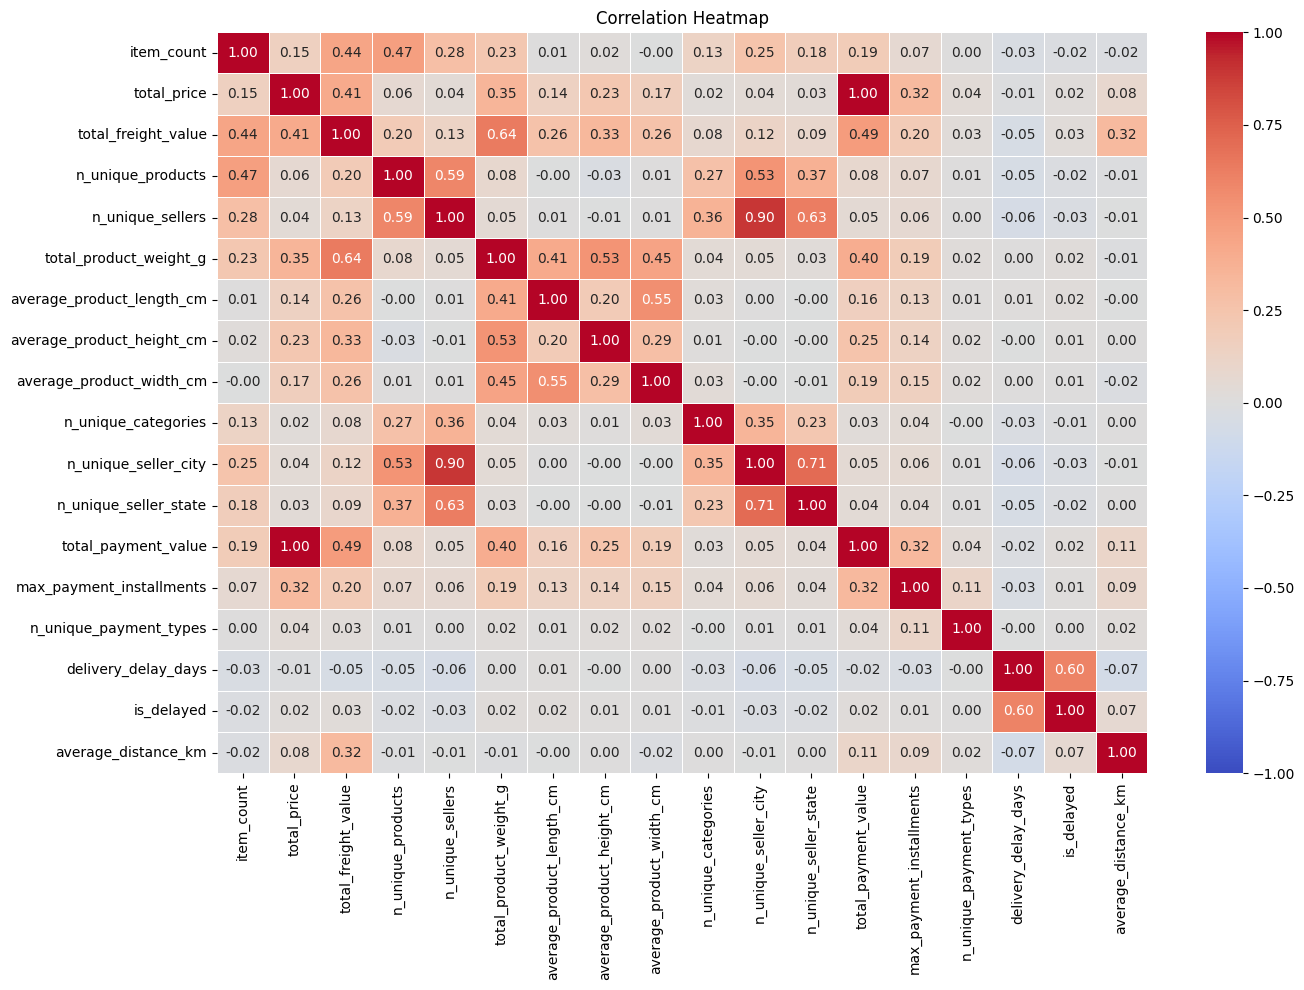

In [ ]:
import matplotlib.pyplot as plt
import seaborn as sns

corr_matrix = experimental_df.corr(numeric_only=True)

plt.figure(figsize=(14, 10))

sns.heatmap(
    corr_matrix,
    annot=True,
    fmt=".2f",
    cmap="coolwarm",
    vmin=-1,
    vmax=1,
    linewidths=0.5
)

plt.title("Correlation Heatmap")
plt.tight_layout()
plt.show()